In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization,
    Input
)

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

# Set random seeds for reproducible results
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
df = pd.read_csv("bank.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


First Five Records:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63    

In [3]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

# Identify the target column automatically
target_candidates = [
    "exited",
    "churn",
    "churned",
    "attrition",
    "target"
]

target_column = None

for col in df.columns:

    if col.strip().lower() in target_candidates:
        target_column = col
        break

if target_column is None:

    print("\nAvailable Columns:", list(df.columns))

    target_column = input("Enter target column name: ").strip()

    if target_column not in df.columns:
        raise ValueError("Target column not found!")

print("\nTarget Column:", target_column)

# Remove records having missing target values
df.dropna(subset=[target_column], inplace=True)

# Separate target variable
y = df[target_column]

# Remove target from input features
X = df.drop(columns=[target_column])

# Remove unnecessary identification columns
# These columns do not represent useful customer behavior.
id_columns = [
    "RowNumber",
    "CustomerId",
    "CustomerID",
    "Surname",
    "ID"
]

X = X.drop(
    columns=[
        col for col in X.columns
        if col.strip().lower() in [c.lower() for c in id_columns]
    ],
    errors="ignore"
)

# Replace infinite values with missing values
X.replace([np.inf, -np.inf], np.nan, inplace=True)

print("\nSelected Input Features:")
print(X.head())

print("\nTarget Distribution:")
print(y.value_counts())



Target Column: Exited

Selected Input Features:
   CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
0          619    France  Female   42       2       0.00              1   
1          608     Spain  Female   41       1   83807.86              1   
2          502    France  Female   42       8  159660.80              3   
3          699    France  Female   39       1       0.00              2   
4          850     Spain  Female   43       2  125510.82              1   

   HasCrCard  IsActiveMember  EstimatedSalary  
0          1               1        101348.88  
1          0               1        112542.58  
2          1               0        113931.57  
3          0               0         93826.63  
4          1               1         79084.10  

Target Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


In [4]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("\nTarget Class Mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

# This practical requires binary classification
if len(label_encoder.classes_) != 2:
    raise ValueError("Target must contain exactly two classes.")

print("\nTarget Encoding Completed!")



Target Class Mapping:
0 = 0
1 = 1

Target Encoding Completed!


In [5]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)



Numerical Features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Categorical Features:
['Geography', 'Gender']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(pd.Series(y_train).value_counts())


Training Data Shape: (8000, 10)
Testing Data Shape: (2000, 10)

Training Class Distribution:
0    6370
1    1630
Name: count, dtype: int64


In [7]:
# Create numerical preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit on training data and transform
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_scaled = preprocessor.transform(X_test)

# Ensure numerical NumPy arrays
X_train_scaled = np.asarray(X_train_scaled, dtype=np.float32)
X_test_scaled = np.asarray(X_test_scaled, dtype=np.float32)

print("\nTraining Data After Normalization:")
print(X_train_scaled[:5])

print("\nTesting Data After Normalization:")
print(X_test_scaled[:5])

print("\nNormalized Training Shape:", X_train_scaled.shape)
print("Normalized Testing Shape:", X_test_scaled.shape)



Training Data After Normalization:
[[ 1.058568    1.7150865   0.68472284 -1.2260588  -0.9102565   0.64104193
  -1.030206    1.0420839   1.          0.          0.          0.
   1.        ]
 [ 0.9136261  -0.6599355  -0.6962018   0.4132877  -0.9102565   0.64104193
  -1.030206   -0.6235564   0.          1.          0.          0.
   1.        ]
 [ 1.0792739  -0.18493108 -1.7318953   0.6016875   0.8088304   0.64104193
   0.97067964  0.3081278   0.          1.          0.          1.
   0.        ]
 [-0.9292073  -0.18493108 -0.00573947 -1.2260588   0.8088304   0.64104193
  -1.030206   -0.29019913  1.          0.          0.          0.
   1.        ]
 [ 0.4270352   0.95507944  0.3394917   0.5483183   0.8088304  -1.5599604
   0.97067964  0.13504224  0.          1.          0.          0.
   1.        ]]

Testing Data After Normalization:
[[-0.6807354  -0.27993196  0.68472284 -1.2260588   0.8088304   0.64104193
  -1.030206   -0.09502138  1.          0.          0.          0.
   1.        ]

In [8]:
input_features = X_train_scaled.shape[1]

# Create the initial ANN model
model = Sequential([

    Input(shape=(input_features,)),

    Dense(16, activation="relu"),

    Dense(8, activation="relu"),

    Dense(1, activation="sigmoid")

])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nInitial Neural Network Model:")
model.summary()



Initial Neural Network Model:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
initial_history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

print("\nInitial Model Training Completed!")


Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7909 - loss: 0.4944 - val_accuracy: 0.8037 - val_loss: 0.4448
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8089 - loss: 0.4302 - val_accuracy: 0.8231 - val_loss: 0.4189
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8167 - loss: 0.4130 - val_accuracy: 0.8281 - val_loss: 0.4045
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8236 - loss: 0.3998 - val_accuracy: 0.8400 - val_loss: 0.3897
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8294 - loss: 0.3870 - val_accuracy: 0.8444 - val_loss: 0.3750
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8409 - loss: 0.3747 - val_accuracy: 0.8537 - val_loss: 0.3618
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8472 - loss: 0.3645 - val_accuracy: 0.8619 - val_loss: 0.3517
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8505 - loss: 0.3573 - val_accuracy: 0.

In [10]:
initial_loss, initial_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("\nInitial Model Results:")

print("Initial Loss:", round(initial_loss, 4))

print(
    "Initial Accuracy:",
    round(initial_accuracy * 100, 2),
    "%"
)


Initial Model Results:
Initial Loss: 0.3374
Initial Accuracy: 86.7 %


In [11]:
# Calculate balanced class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("\nClass Weights:")
print(class_weights)




Class Weights:
{0: 0.6279434850863422, 1: 2.4539877300613497}


In [12]:
improved_model = Sequential([

    Input(shape=(input_features,)),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    BatchNormalization(),

    Dropout(0.30),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    BatchNormalization(),

    Dropout(0.20),

    Dense(1, activation="sigmoid")

])

# Compile improved model
improved_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nImproved Neural Network Model:")
improved_model.summary()



Improved Neural Network Model:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 192 (768.00 B)

In [13]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

print("\nCallbacks Created Successfully!")


Callbacks Created Successfully!


In [14]:
improved_history = improved_model.fit(

    X_train_scaled,
    y_train,

    epochs=50,

    batch_size=32,

    validation_split=0.20,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

print("\nImproved Model Training Completed!")

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6217 - loss: 0.7213 - val_accuracy: 0.7756 - val_loss: 0.6045 - learning_rate: 0.0010
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6919 - loss: 0.6418 - val_accuracy: 0.7694 - val_loss: 0.5702 - learning_rate: 0.0010
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7359 - loss: 0.6054 - val_accuracy: 0.7656 - val_loss: 0.5462 - learning_rate: 0.0010
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7394 - loss: 0.5884 - val_accuracy: 0.7738 - val_loss: 0.5356 - learning_rate: 0.0010
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7522 - loss: 0.5628 - val_accuracy: 0.7781 - val_loss: 0.5194 - learning_rate: 0.0010
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7528 - loss: 0.5574 - val_accuracy: 0.7925 - val_loss: 0.5044 - learning_rate: 0.0010
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7677 - loss: 0.5481 - 

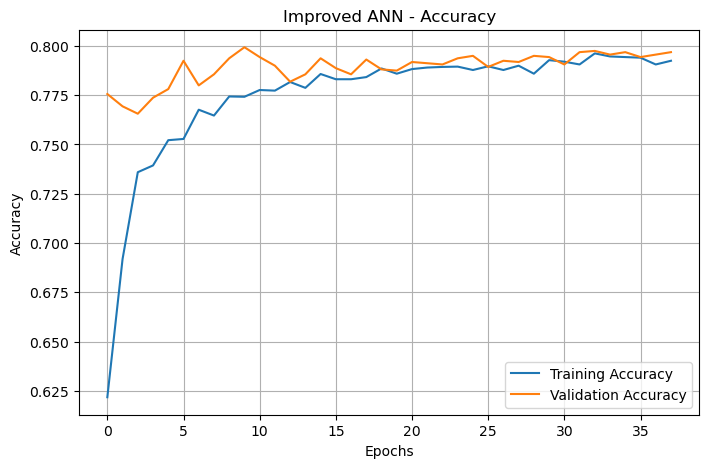

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    improved_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    improved_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Improved ANN - Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()


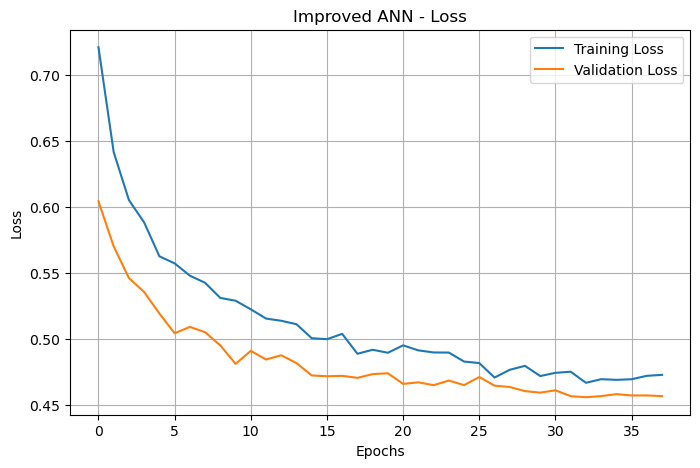

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    improved_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    improved_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Improved ANN - Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()



In [17]:

test_loss, test_accuracy = improved_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("\nImproved Model Evaluation:")

print("Test Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)



Improved Model Evaluation:
Test Loss: 0.4698
Test Accuracy: 78.6 %


In [18]:
# Predict churn probabilities
y_probability = improved_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

# Convert probabilities into binary class labels
y_pred = (y_probability >= 0.5).astype(int)

print("\nFirst 10 Actual Values:")
print(y_test[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])



First 10 Actual Values:
[0 0 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 0 1 0 1 1 0]


In [19]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nFinal Accuracy Score:", round(accuracy, 4))

print(
    "Accuracy Percentage:",
    round(accuracy * 100, 2),
    "%"
)



Final Accuracy Score: 0.786
Accuracy Percentage: 78.6 %


In [20]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

# Extract matrix values
tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative:", tn)

print("False Positive:", fp)

print("False Negative:", fn)

print("True Positive:", tp)




Confusion Matrix:
[[1264  329]
 [  99  308]]

True Negative: 1264
False Positive: 329
False Negative: 99
True Positive: 308


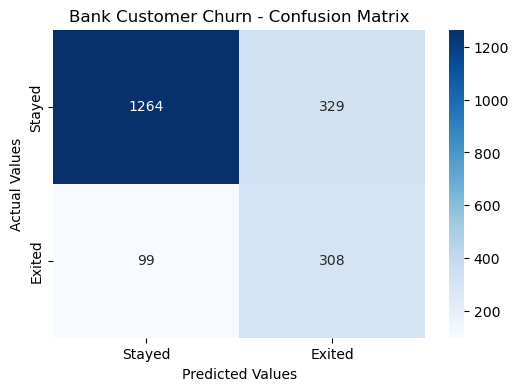

In [21]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Exited"],
    yticklabels=["Stayed", "Exited"]
)

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.title("Bank Customer Churn - Confusion Matrix")

plt.show()


In [22]:
precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

error_rate = 1 - accuracy

print("\nPrecision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))

print("Error Rate:", round(error_rate, 4))



Precision: 0.4835
Recall: 0.7568
F1 Score: 0.59
Error Rate: 0.214


In [23]:
comparison = pd.DataFrame({

    "Model": [
        "Initial ANN",
        "Improved ANN"
    ],

    "Accuracy": [
        initial_accuracy,
        accuracy_score(
            y_test,
            (model.predict(X_test_scaled, verbose=0).ravel() >= 0.5).astype(int)
        )
    ],

    "Test Loss": [
        initial_loss,
        test_loss
    ]

})

print("\nMODEL PERFORMANCE COMPARISON:")

print(comparison.to_string(index=False))




MODEL PERFORMANCE COMPARISON:
       Model  Accuracy  Test Loss
 Initial ANN     0.867   0.337392
Improved ANN     0.867   0.469792


In [24]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Stayed (0)", "Exited (1)"],
        zero_division=0
    )
)



Classification Report:
              precision    recall  f1-score   support

  Stayed (0)       0.93      0.79      0.86      1593
  Exited (1)       0.48      0.76      0.59       407

    accuracy                           0.79      2000
   macro avg       0.71      0.78      0.72      2000
weighted avg       0.84      0.79      0.80      2000

